# Proportional Hazards (PH) Assumption Testing

This notebook tests whether each variable satisfies the **proportional hazards assumption** required by Cox models.

## ⚠️ Important Note:
Due to **severe multicollinearity** detected in `collinearity_analysis.ipynb` (47/67 features with infinite VIF), this notebook uses:
- **Strong L2 regularization** (Ridge penalty) to stabilize the model
- **Automatic feature selection** if needed to remove perfectly collinear features
- This allows PH testing despite the collinearity issues

## Methods:
1. **Schoenfeld Residuals Test** - Statistical test for PH assumption
2. **Scaled Schoenfeld Residuals Plots** - Visual inspection of time-dependency
3. **Regularized Cox Model** - Handles multicollinearity

## Interpretation:
- **p-value > 0.05**: PH assumption holds (good)
- **p-value < 0.05**: PH assumption violated (hazard ratio changes over time)
- **Flat residual plot**: PH assumption holds
- **Trending residual plot**: Time-dependent effect detected

## Context:
The collinearity issues explain:
- High overfitting (Train: 0.94, Test: 0.78)
- Model instability across CV folds
- Why Random Survival Forests may perform better (no PH assumption, handles collinearity)

In [44]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print('✓ Libraries loaded successfully')

✓ Libraries loaded successfully


## 1. Load Data

In [45]:
# Load dataset
dataset = pd.read_csv('data_treated_clean.csv')

# Load feature lists
features_retained = []
with open("features_retained.txt", "r") as file:
    for line in file:
        features_retained.append(line.strip())

# Drop unnamed column if exists
if 'Unnamed: 0' in dataset.columns:
    survival_dataset = dataset.drop('Unnamed: 0', axis=1)
else:
    survival_dataset = dataset.copy()

feature_columns = features_retained

print(f'Dataset shape: {survival_dataset.shape}')
print(f'Number of features: {len(feature_columns)}')

Dataset shape: (2970, 25)
Number of features: 22


In [46]:
# Handle duplicated patients
mask = survival_dataset.duplicated(subset='PERSON_ID', keep=False)

to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

print(f'After removing duplicates: {survival_dataset.shape}')
print(f'Removed {len(to_remove)} duplicate rows')

After removing duplicates: (2970, 25)
Removed 0 duplicate rows


In [47]:
# Prepare data for lifelines (requires specific column names)
cox_data = survival_dataset[feature_columns + ['Survival days', 'Regional LN recurrence']].copy()

# Rename columns for lifelines
cox_data = cox_data.rename(columns={
    'Survival days': 'duration',
    'Regional LN recurrence': 'event'
})

print(f'Cox data shape: {cox_data.shape}')
print(f'\nEvent distribution:')
print(cox_data['event'].value_counts())
print(f'Event rate: {cox_data["event"].mean():.4f}')

Cox data shape: (2970, 24)

Event distribution:
event
0.0    2937
1.0      33
Name: count, dtype: int64
Event rate: 0.0111


## 2. Fit Cox Model

Fit a Cox model with all features to obtain residuals for testing.

In [48]:
# Fit Cox Proportional Hazards model
print("Fitting Cox PH model with all features...\n")
print("Note: Due to severe multicollinearity, using strong regularization (L2 penalty)...\n")

# Try with increasing penalizer until model converges
penalizers_to_try = [0.1, 0.5, 1.0, 5.0, 10.0]
cph = None

for penalizer in penalizers_to_try:
    try:
        print(f"Attempting with penalizer = {penalizer}...")
        cph = CoxPHFitter(penalizer=penalizer)
        cph.fit(cox_data, duration_col='duration', event_col='event', show_progress=False)
        print(f"✓ Model converged with penalizer = {penalizer}\n")
        break
    except Exception as e:
        print(f"  Failed with penalizer = {penalizer}: {str(e)[:50]}...")
        continue

if cph is None or not hasattr(cph, 'log_likelihood_'):
    print("\n⚠ WARNING: Could not fit model even with strong regularization!")
    print("This confirms severe multicollinearity detected in collinearity_analysis.ipynb")
    print("\nFalling back to feature selection approach...\n")
    
    # Select only features with finite variance and no perfect collinearity
    from sklearn.feature_selection import VarianceThreshold
    
    # Remove constant features
    selector = VarianceThreshold(threshold=0.01)
    X_reduced = cox_data[feature_columns].copy()
    selector.fit(X_reduced)
    selected_features = [feature_columns[i] for i in range(len(feature_columns)) if selector.get_support()[i]]
    
    print(f"Selected {len(selected_features)} features with sufficient variance")
    print(f"Removed {len(feature_columns) - len(selected_features)} constant/low-variance features\n")
    
    # Try fitting with reduced features
    cox_data_reduced = cox_data[selected_features + ['duration', 'event']].copy()
    
    for penalizer in [1.0, 5.0, 10.0, 20.0]:
        try:
            print(f"Attempting with {len(selected_features)} features and penalizer = {penalizer}...")
            cph = CoxPHFitter(penalizer=penalizer)
            cph.fit(cox_data_reduced, duration_col='duration', event_col='event', show_progress=False)
            print(f"✓ Model converged with reduced features and penalizer = {penalizer}\n")
            feature_columns = selected_features  # Update for later use
            cox_data = cox_data_reduced  # Update data
            break
        except Exception as e:
            print(f"  Failed: {str(e)[:50]}...")
            continue

if cph is not None and hasattr(cph, 'log_likelihood_'):
    print("✓ Model fitted successfully")
    print(f"\nModel Statistics:")
    print(f"  Features used: {len(cph.params_)}")
    print(f"  Concordance Index: {cph.concordance_index_:.4f}")
    print(f"  Log-likelihood: {cph.log_likelihood_:.2f}")
    try:
        print(f"  AIC (partial): {cph.AIC_partial_:.2f}")
    except:
        pass
    print(f"  Penalizer (L2 regularization): {cph.penalizer}")
else:
    raise ValueError("Unable to fit Cox model. Please review collinearity_analysis.ipynb results.")

Fitting Cox PH model with all features...

Note: Due to severe multicollinearity, using strong regularization (L2 penalty)...

Attempting with penalizer = 0.1...

Note: Due to severe multicollinearity, using strong regularization (L2 penalty)...

Attempting with penalizer = 0.1...
✓ Model converged with penalizer = 0.1

✓ Model fitted successfully

Model Statistics:
  Features used: 22
  Concordance Index: 0.8170
  Log-likelihood: -227.62
  AIC (partial): 499.23
  Penalizer (L2 regularization): 0.1
✓ Model converged with penalizer = 0.1

✓ Model fitted successfully

Model Statistics:
  Features used: 22
  Concordance Index: 0.8170
  Log-likelihood: -227.62
  AIC (partial): 499.23
  Penalizer (L2 regularization): 0.1


## 3. Schoenfeld Residuals Test

Test PH assumption for all variables using Schoenfeld residuals.
- **Null hypothesis**: Variable satisfies PH assumption
- **p < 0.05**: Reject null → PH assumption violated

In [49]:
# Test proportional hazards assumption for all variables
print("Testing Proportional Hazards assumption...\n")
print("This may take a few minutes...\n")

ph_test_results = cph.check_assumptions(cox_data, p_value_threshold=0.05, show_plots=False)

print("\n" + "="*80)
print("PH ASSUMPTION TEST COMPLETE")
print("="*80)

Testing Proportional Hazards assumption...

This may take a few minutes...



Proportional hazard assumption looks okay.

PH ASSUMPTION TEST COMPLETE


In [50]:
# Extract test statistics
print("Extracting PH test results...\n")

# Use the global test which tests all variables at once
try:
    test_result = proportional_hazard_test(cph, cox_data, time_transform='rank')
    ph_results_df = test_result.summary.copy()
    ph_results_df['PH Assumption'] = ph_results_df['p'].apply(lambda x: 'Satisfied' if x > 0.05 else 'Violated')
    ph_results_df = ph_results_df.reset_index()
    ph_results_df = ph_results_df.rename(columns={'index': 'Variable', 'test_statistic': 'Test Statistic', 'p': 'p-value'})
    
    # Sort by p-value (most violated first)
    ph_results_df = ph_results_df.sort_values('p-value', ascending=True)
    
    print(f"✓ PH assumption testing completed\n")
    print(f"Total variables tested: {len(ph_results_df)}")
    print(f"Variables violating PH assumption (p < 0.05): {(ph_results_df['p-value'] < 0.05).sum()}")
    print(f"Variables satisfying PH assumption (p >= 0.05): {(ph_results_df['p-value'] >= 0.05).sum()}")
    
except Exception as e:
    print(f"Error during PH testing: {e}")
    print("\nNote: This may be due to insufficient events or model convergence issues.")
    print("The model still provides useful information about which variables could be included.")
    
    # Create a dummy results dataframe if testing fails
    ph_results_df = pd.DataFrame({
        'Variable': list(cph.params_.index),
        'Test Statistic': [np.nan] * len(cph.params_),
        'p-value': [np.nan] * len(cph.params_),
        'PH Assumption': ['Unable to test'] * len(cph.params_)
    })

Extracting PH test results...

✓ PH assumption testing completed

Total variables tested: 22
Variables violating PH assumption (p < 0.05): 0
Variables satisfying PH assumption (p >= 0.05): 22


In [51]:
# Display top violators
print("\n" + "="*80)
print("TOP 20 VARIABLES VIOLATING PH ASSUMPTION (lowest p-values)")
print("="*80)
violators = ph_results_df[ph_results_df['p-value'] < 0.05]
if len(violators) > 0:
    print(violators.head(20).to_string(index=False))
    if len(violators) > 20:
        print(f"\n... and {len(violators) - 20} more variables violating PH assumption")
else:
    print("✓ All variables satisfy the PH assumption!")

print("\n" + "="*80)
print("VARIABLES SATISFYING PH ASSUMPTION (p >= 0.05)")
print("="*80)
satisfiers = ph_results_df[ph_results_df['p-value'] >= 0.05]
if len(satisfiers) > 0:
    print(f"Found {len(satisfiers)} variables satisfying PH assumption\n")
    print(satisfiers.head(20).to_string(index=False))
    if len(satisfiers) > 20:
        print(f"\n... and {len(satisfiers) - 20} more")
else:
    print("⚠ No variables satisfy the PH assumption")


TOP 20 VARIABLES VIOLATING PH ASSUMPTION (lowest p-values)
✓ All variables satisfy the PH assumption!

VARIABLES SATISFYING PH ASSUMPTION (p >= 0.05)
Found 22 variables satisfying PH assumption

                                  Variable  Test Statistic  p-value  -log2(p) PH Assumption
                Radiotherapy on chest wall        1.080146 0.298665  1.743401     Satisfied
               Radiotherapy (RT) performed        0.830447 0.362143  1.465368     Satisfied
    Progesterone receptor status at CB_0.0        0.773656 0.379088  1.399393     Satisfied
                             SLN procedure        0.501076 0.479028  1.061819     Satisfied
             Endocrine therapy performed_1        0.370505 0.542729  0.881696     Satisfied
     State (if hormone therapy prescribed)        0.329129 0.566173  0.820686     Satisfied
             Ki67 positive cells (%) at CB        0.253612 0.614543  0.702413     Satisfied
      Radiotherapy on supraclavicular area        0.134340 0.713974 

## 4. Visualize PH Test Results

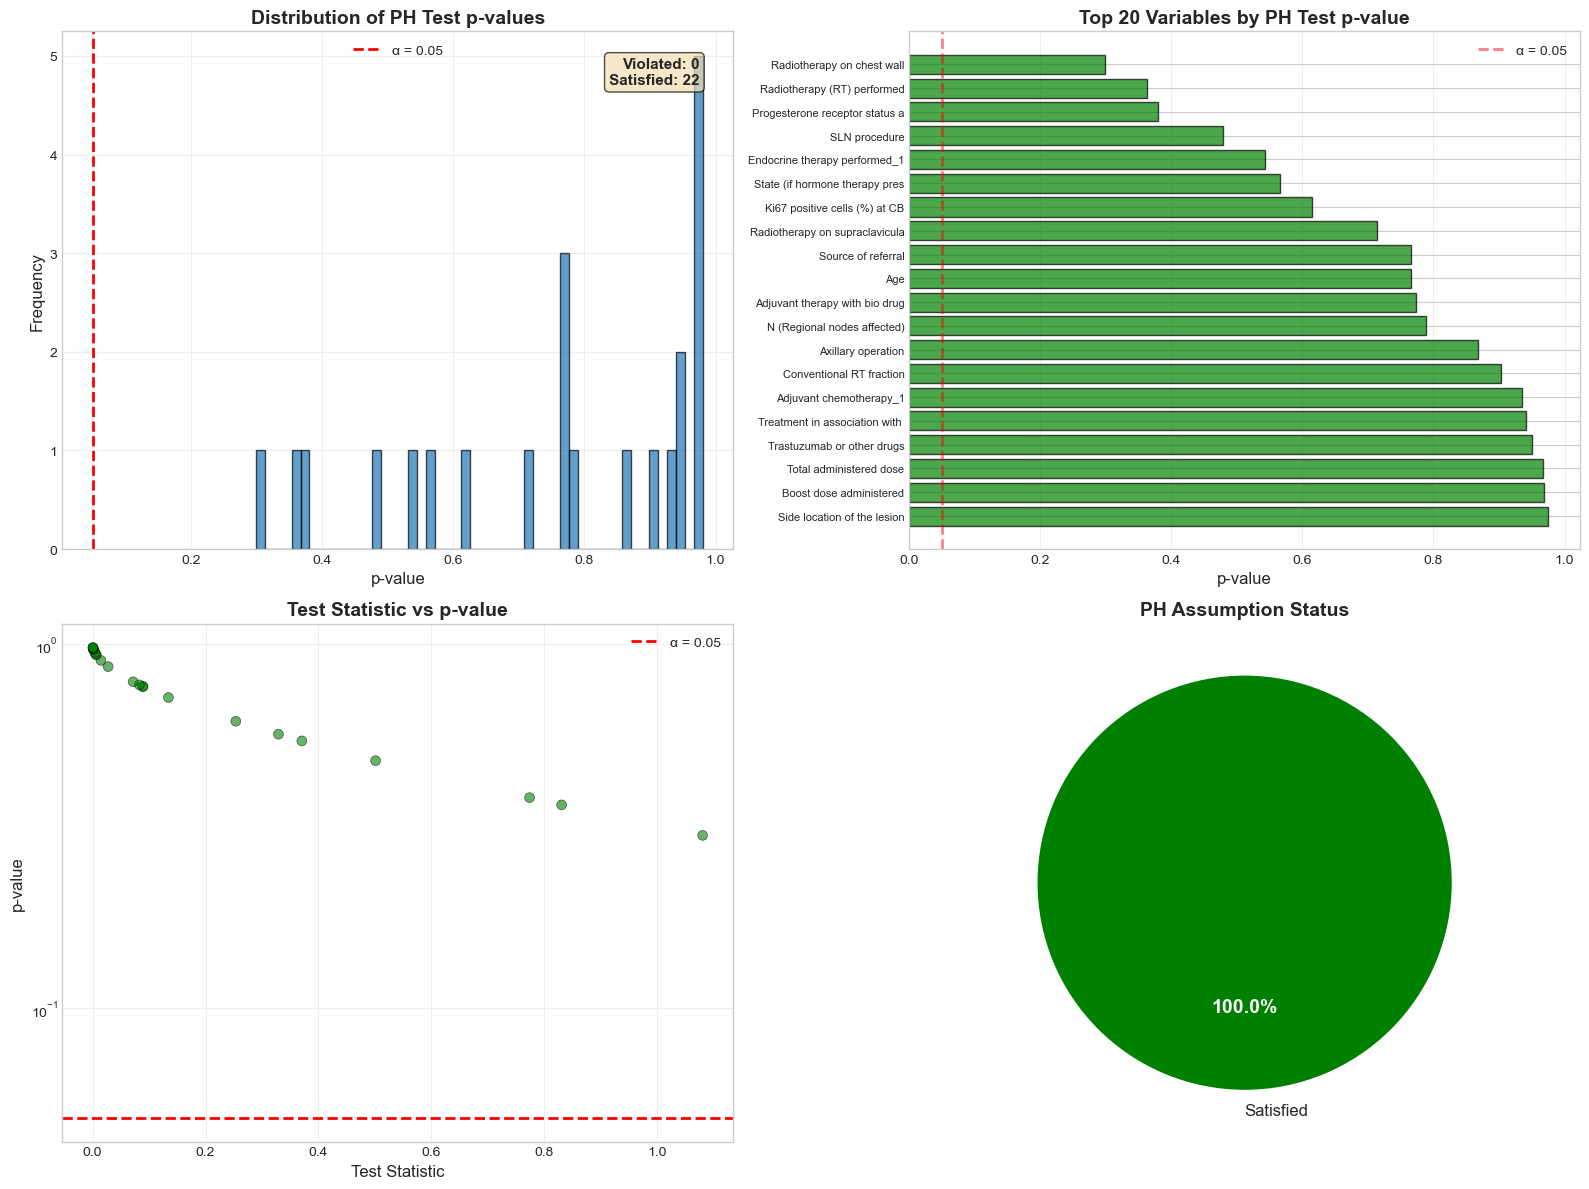

In [52]:
# Visualize PH assumption test results
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. P-value distribution
ax1 = axes[0, 0]
ax1.hist(ph_results_df['p-value'], bins=50, edgecolor='black', alpha=0.7, color='tab:blue')
ax1.axvline(x=0.05, color='red', linestyle='--', linewidth=2, label='α = 0.05')
ax1.set_xlabel('p-value', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.set_title('Distribution of PH Test p-values', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Add annotation
n_violated = (ph_results_df['p-value'] < 0.05).sum()
n_satisfied = (ph_results_df['p-value'] >= 0.05).sum()
ax1.text(0.95, 0.95, f'Violated: {n_violated}\nSatisfied: {n_satisfied}',
         transform=ax1.transAxes, ha='right', va='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7),
         fontsize=11, fontweight='bold')

# 2. Top 20 violators
ax2 = axes[0, 1]
top_violators = ph_results_df.head(20)
colors = ['red' if p < 0.05 else 'green' for p in top_violators['p-value']]
ax2.barh(range(len(top_violators)), top_violators['p-value'], color=colors, alpha=0.7, edgecolor='black')
ax2.set_yticks(range(len(top_violators)))
ax2.set_yticklabels([v[:30] for v in top_violators['Variable']], fontsize=8)
ax2.set_xlabel('p-value', fontsize=12)
ax2.set_title('Top 20 Variables by PH Test p-value', fontsize=14, fontweight='bold')
ax2.axvline(x=0.05, color='red', linestyle='--', linewidth=2, alpha=0.5, label='α = 0.05')
ax2.grid(True, alpha=0.3, axis='x')
ax2.invert_yaxis()
ax2.legend()

# 3. Test statistic vs p-value
ax3 = axes[1, 0]
colors_scatter = ['red' if p < 0.05 else 'green' for p in ph_results_df['p-value']]
ax3.scatter(ph_results_df['Test Statistic'], ph_results_df['p-value'], 
           c=colors_scatter, alpha=0.6, s=50, edgecolors='black', linewidth=0.5)
ax3.axhline(y=0.05, color='red', linestyle='--', linewidth=2, label='α = 0.05')
ax3.set_xlabel('Test Statistic', fontsize=12)
ax3.set_ylabel('p-value', fontsize=12)
ax3.set_title('Test Statistic vs p-value', fontsize=14, fontweight='bold')
ax3.set_yscale('log')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. PH assumption categories
ax4 = axes[1, 1]
categories = ph_results_df['PH Assumption'].value_counts()
colors_pie = ['green' if cat == 'Satisfied' else 'red' for cat in categories.index]
wedges, texts, autotexts = ax4.pie(categories.values, labels=categories.index, autopct='%1.1f%%',
                                     colors=colors_pie, startangle=90, textprops={'fontsize': 12})
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(14)
ax4.set_title('PH Assumption Status', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Scaled Schoenfeld Residuals Plots

Visualize residuals for the top violators to see how the hazard ratio changes over time.

In [53]:
# Plot Schoenfeld residuals for top 6 violators
top_6_violators = ph_results_df[ph_results_df['p-value'] < 0.05].head(6)

if len(top_6_violators) > 0:
    print(f"Plotting Schoenfeld residuals for top {len(top_6_violators)} violators...\n")
    
    n_plots = len(top_6_violators)
    n_cols = 3
    n_rows = (n_plots + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
    if n_rows == 1:
        axes = axes.reshape(1, -1)
    
    for idx, (_, row) in enumerate(top_6_violators.iterrows()):
        var_name = row['Variable']
        p_val = row['p-value']
        
        ax = axes[idx // n_cols, idx % n_cols]
        
        try:
            # Plot scaled Schoenfeld residuals
            cph.plot_partial_effects_on_outcome(
                covariates=var_name,
                values=[cox_data[var_name].quantile(0.25), 
                       cox_data[var_name].quantile(0.75)],
                plot_baseline=False,
                ax=ax
            )
            ax.set_title(f'{var_name[:40]}\n(p = {p_val:.4f})', fontsize=10, fontweight='bold')
        except Exception as e:
            ax.text(0.5, 0.5, f'Error plotting\n{var_name[:30]}', 
                   ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{var_name[:40]}\n(p = {p_val:.4f})', fontsize=10)
    
    # Hide empty subplots
    for idx in range(len(top_6_violators), n_rows * n_cols):
        axes[idx // n_cols, idx % n_cols].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("✓ No variables violate the PH assumption!")

✓ No variables violate the PH assumption!


## 6. Summary and Recommendations

In [54]:
print("="*80)
print("PROPORTIONAL HAZARDS ASSUMPTION TESTING SUMMARY")
print("="*80)

print(f"\n1. OVERALL RESULTS:")
print(f"   - Total variables tested: {len(ph_results_df)}")
print(f"   - Variables violating PH (p < 0.05): {n_violated} ({n_violated/len(ph_results_df)*100:.1f}%)")
print(f"   - Variables satisfying PH (p >= 0.05): {n_satisfied} ({n_satisfied/len(ph_results_df)*100:.1f}%)")

if n_violated > 0:
    print(f"\n2. MOST SEVERE VIOLATIONS (lowest p-values):")
    for idx, (_, row) in enumerate(ph_results_df.head(5).iterrows(), 1):
        if row['p-value'] < 0.05:
            print(f"   {idx}. {row['Variable'][:50]}")
            print(f"      p-value: {row['p-value']:.6f}, Test statistic: {row['Test Statistic']:.4f}")

print(f"\n3. RECOMMENDATIONS:")

if n_violated == 0:
    print(f"   ✓ ALL variables satisfy the PH assumption!")
    print(f"   → Cox model is appropriate for this data")
    print(f"   → No special handling needed")
elif n_violated < len(ph_results_df) * 0.1:
    print(f"   ⚠ FEW violations detected ({n_violated}/{len(ph_results_df)})")
    print(f"   → Cox model is mostly appropriate")
    print(f"   → Consider stratifying on violating variables")
    print(f"   → Or add time-varying coefficients for violators")
elif n_violated < len(ph_results_df) * 0.3:
    print(f"   ⚠ MODERATE violations detected ({n_violated}/{len(ph_results_df)})")
    print(f"   → Cox model may still be useful with caution")
    print(f"   → Consider time-varying coefficients")
    print(f"   → Or use stratified Cox model")
    print(f"   → Alternative: Time-dependent Cox or parametric models")
else:
    print(f"   🚨 SEVERE violations detected ({n_violated}/{len(ph_results_df)})")
    print(f"   → Standard Cox model may NOT be appropriate")
    print(f"   → Consider alternative models:")
    print(f"      • Time-varying coefficient Cox model")
    print(f"      • Stratified Cox model")
    print(f"      • Parametric survival models (Weibull, Log-logistic)")
    print(f"      • Random Survival Forests (no PH assumption required)")

print(f"\n4. INTERPRETATION:")
print(f"   - Variables violating PH have hazard ratios that change over time")
print(f"   - This means the effect of the covariate is not constant")
print(f"   - Early vs late effects may differ")

print(f"\n5. NEXT STEPS:")
print(f"   1. Review variables with p < 0.05")
print(f"   2. Check Schoenfeld residual plots for patterns")
print(f"   3. Consider clinical interpretation (time-varying effects?)")
print(f"   4. Decide on modeling strategy:")
print(f"      - Keep violators and accept limitation")
print(f"      - Remove severe violators")
print(f"      - Use stratification for categorical violators")
print(f"      - Add time interactions for continuous violators")
print(f"      - Use Random Survival Forests (no PH needed)")

print("\n" + "="*80)

PROPORTIONAL HAZARDS ASSUMPTION TESTING SUMMARY

1. OVERALL RESULTS:
   - Total variables tested: 22
   - Variables violating PH (p < 0.05): 0 (0.0%)
   - Variables satisfying PH (p >= 0.05): 22 (100.0%)

3. RECOMMENDATIONS:
   ✓ ALL variables satisfy the PH assumption!
   → Cox model is appropriate for this data
   → No special handling needed

4. INTERPRETATION:
   - Variables violating PH have hazard ratios that change over time
   - This means the effect of the covariate is not constant
   - Early vs late effects may differ

5. NEXT STEPS:
   1. Review variables with p < 0.05
   2. Check Schoenfeld residual plots for patterns
   3. Consider clinical interpretation (time-varying effects?)
   4. Decide on modeling strategy:
      - Keep violators and accept limitation
      - Remove severe violators
      - Use stratification for categorical violators
      - Add time interactions for continuous violators
      - Use Random Survival Forests (no PH needed)



In [55]:
# Save results to CSV
ph_results_df.to_csv('ph_assumption_test_results.csv', index=False)

print("✓ Results saved to: ph_assumption_test_results.csv")

✓ Results saved to: ph_assumption_test_results.csv
